# Лабораторная работа №1: Линейная регрессия
## Предсказание кредитного скоринга (RiskScore)

### Описание задачи
В рамках данной лабораторной работы решается задача регрессии в формате соревнования Kaggle:
- **Целевая переменная**: `RiskScore` (вещественное число, отражающее оценку кредитного риска заемщика).
- **Ограничение**: Разрешено использовать **только линейную регрессию** (в том числе для отбора признаков сторонние модели использовать запрещено).
- **Критерий допуска к защите**: Получение значения метрики **MSE < 25.00** на тестовой выборке (`test.csv`).
- **Целевой ориентир высокого качества**: **MSE < 18.00**.

### Разбалловка работы (Всего 15 баллов):
1. **Разведочный анализ данных (EDA)** — 1 балл
2. **Нормализация данных (Z-Score и Min-Max)** — 1 балл
3. **Реализация класса Linear Regression (Аналитика, GD, SGD)** — 3 балла
4. **Реализация кросс-валидации (K-Fold и Leave-One-Out)** — 3 балла
5. **Реализация метрик качества (MSE, MAE, R², MAPE)** — 2 балла (по 0.5 за каждую)
6. **Бонусные баллы**:
   - Реализация L1, L2, ElasticNet регуляризации — +2 балла
   - Реализация Lp-регуляризации — +1 балл
7. **Защита лабораторной работы** — 5 баллов


## 0. Импорт библиотек и первичные настройки
Подключаем необходимые базовые библиотеки:
- `numpy` — для векторных и матричных математических операций;
- `pandas` — для работы с таблицами и датасетами;
- `matplotlib.pyplot` и `seaborn` — для построения графиков и тепловых карт;
- `sklearn` — исключительно для контрольной проверки написанных нами функций и алгоритмов.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка красивого стиля для графиков
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# Фиксация случайного сида для воспроизводимости
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 1. Разведочный анализ данных (EDA) [1 балл]
**Цель этапа**:
- Загрузить данные из `data/train.csv` и `data/test.csv`.
- Изучить размеры, типы признаков, пропуски (NaN).
- Исследовать целевую переменную `RiskScore` (распределение, аномалии, выбросы).
- Исследовать признаки и их влияние на `RiskScore`.
- Построить матрицу корреляций и графики зависимостей.
- Сформулировать аналитические выводы.


### 1.1 Загрузка и первичный осмотр данных
Загрузим обучающую и тестовую выборки, выведем их размерности и первые 5 строк.

In [2]:
# Загрузка обучающей и тестовой выборок
train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

print(f"Размер train.csv: {train_df.shape} (строк, столбцов)")
print(f"Размер test.csv:  {test_df.shape} (строк, столбцов)")

train_df.head()


Размер train.csv: (11017, 35) (строк, столбцов)
Размер test.csv:  (5000, 35) (строк, столбцов)


,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,...,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,RiskScore
0,2010-06-26,27.0,66829.0,549.0,17290.0,60.0,Divorced,1.0,Rent,1095.0,...,4.0,Employed,Associate,4.0,35067.0,0.257790,0.251465,508.970230,0.288013,66.176500
1,1996-09-23,55.0,172147.0,850.0,16110.0,36.0,Widowed,1.0,Mortgage,211.0,...,2.0,Employed,High School,33.0,27001.0,0.086110,0.093173,514.675859,0.050585,28.495737
2,2015-01-19,51.0,300000.0,850.0,38436.0,36.0,Married,0.0,Mortgage,546.0,...,3.0,Employed,Bachelor,28.0,278382.0,0.108436,0.115443,1268.276385,0.072571,34.488104
3,1981-05-12,25.0,34683.0,847.0,19186.0,48.0,Married,0.0,Other,153.0,...,3.0,Employed,High School,0.0,9224.0,0.100686,0.112822,498.505187,0.225415,36.910753
4,1995-05-07,55.0,300000.0,850.0,30437.0,48.0,Single,2.0,Rent,562.0,...,5.0,Employed,Bachelor,31.0,4502.0,0.110437,0.089037,756.035156,0.052721,31.347091


### 1.2 Анализ структуры датасета и очистка пустых строк
Проверим наличие полностью пустых строк в обучающей выборке, а также изучим распределение пропусков (`NaN`) по столбцам.

In [3]:
# 1. Проверим наличие полностью пустых строк (где все значения NaN)
empty_rows_count = train_df.isnull().all(axis=1).sum()
print(f"Полностью пустых строк в train.csv: {empty_rows_count}")

# Удаляем полностью пустые строки
train_df = train_df.dropna(how="all").reset_index(drop=True)
print(f"Размер train_df после удаления пустых строк: {train_df.shape}")

# 2. Проверим пропуски по признакам в train_df
missing_values = train_df.isnull().sum()
missing_cols = missing_values[missing_values > 0]
print("\nСтолбцы с пропусками и их количество:")
print(missing_cols)

# 3. Проверим пропуски в тестовой выборке
test_missing = test_df.isnull().sum().sum()
print(f"\nСуммарное количество пропусков в test.csv: {test_missing}")

Полностью пустых строк в train.csv: 530
Размер train_df после удаления пустых строк: (10487, 35)

Столбцы с пропусками и их количество:
CreditScore               501
LoanAmount                501
MonthlyDebtPayments       501
BankruptcyHistory         501
LoanPurpose               501
CheckingAccountBalance    501
TotalAssets               501
NetWorth                  501
BaseInterestRate          501
dtype: int64

Суммарное количество пропусков в test.csv: 0


### 1.3 Исследование целевой переменной `RiskScore` и отлов выбросов
**Целевая переменная** — это то, что мы предсказываем. 
Оценка риска (`RiskScore`) по смыслу задачи должна лежать в пределах разумной шкалы скоринга (например, от 0 до 100).

Посмотрим на числовые характеристики столбца: среднее (`mean`), минимум (`min`), максимум (`max`) и квартили.

Статистика RiskScore до очистки:
count    1.048700e+04
mean    -2.569878e+04
std      1.431675e+06
min     -9.999999e+06
25%      3.256475e+01
50%      4.411876e+01
75%      6.535690e+01
max      1.000000e+07
Name: RiskScore, dtype: float64

Аномалий меньше 0: 121 (значения порядка -9 999 999)
Аномалий больше 100: 94 (значения порядка 10 000 000)


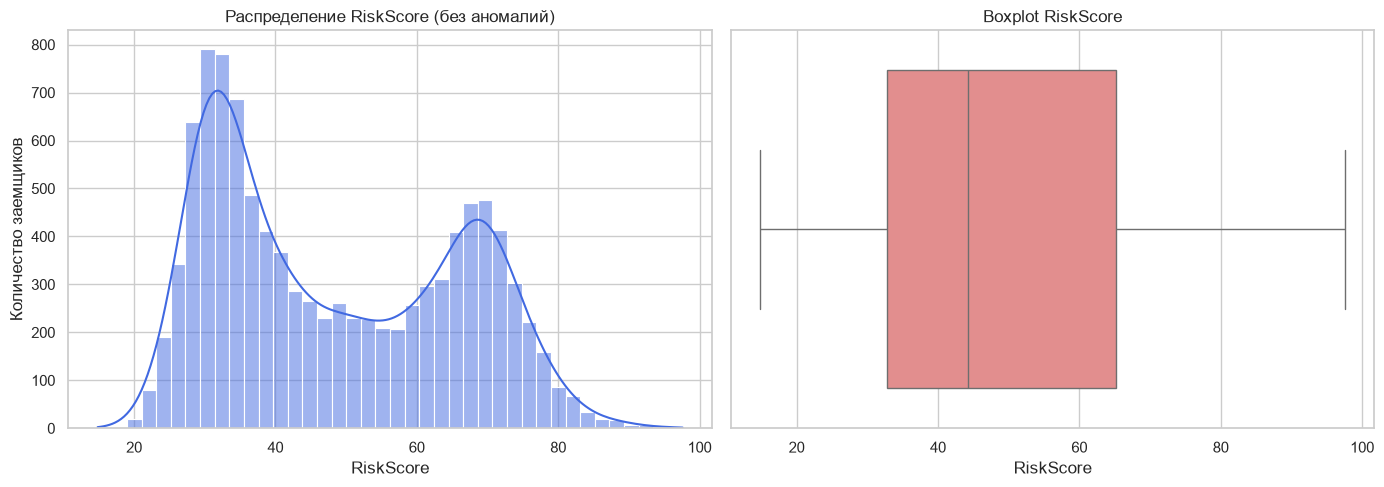

Размер обучающей выборки после удаления аномалий: (10272, 35)
Новое среднее: 48.36, медиана: 44.20


In [4]:
# Базовые статистики RiskScore
print("Статистика RiskScore до очистки:")
print(train_df["RiskScore"].describe())

# Подсчет аномальных значений
outliers_low = (train_df["RiskScore"] < 0).sum()
outliers_high = (train_df["RiskScore"] > 100).sum()
print(f"\nАномалий меньше 0: {outliers_low} (значения порядка -9 999 999)")
print(f"Аномалий больше 100: {outliers_high} (значения порядка 10 000 000)")

# Визуализация распределения RiskScore (в адекватном диапазоне от 0 до 100)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

valid_risk = train_df[(train_df["RiskScore"] >= 0) & (train_df["RiskScore"] <= 100)]["RiskScore"]

# Гистограмма с кривой плотности KDE
sns.histplot(valid_risk, kde=True, bins=40, color="royalblue", ax=axes[0])
axes[0].set_title("Распределение RiskScore (без аномалий)")
axes[0].set_xlabel("RiskScore")
axes[0].set_ylabel("Количество заемщиков")

# Boxplot (ящик с усами)
sns.boxplot(x=valid_risk, color="lightcoral", ax=axes[1])
axes[1].set_title("Boxplot RiskScore")
axes[1].set_xlabel("RiskScore")

plt.tight_layout()
plt.show()

# Удаляем аномалии целевой переменной из train_df
train_df = train_df[(train_df["RiskScore"] >= 0) & (train_df["RiskScore"] <= 100)].reset_index(drop=True)
print(f"Размер обучающей выборки после удаления аномалий: {train_df.shape}")
print(f"Новое среднее: {train_df['RiskScore'].mean():.2f}, медиана: {train_df['RiskScore'].median():.2f}")

### 1.4 Матрица корреляций (Correlation Matrix)
**Корреляция Пирсона** показывает силу и направление линейной связи между признаками (от -1 до +1):
- **Близко к +1**: Прямая зависимость (одно растет — другое тоже растет).
- **Близко к -1**: Обратная зависимость (одно растет — другое падает).
- **Около 0**: Линейная связь отсутствует.

Также матрица позволяет обнаружить **мультиколлинеарность** — когда два входных признака почти идеально дублируют друг друга (например, возраст и трудовой стаж, или годовой доход и месячный доход). Для линейной регрессии это опасно, так как приводит к неустойчивости матричных вычислений.

--- Топ факторов, увеличивающих риск (положительная корреляция) ---
BaseInterestRate          0.758712
InterestRate              0.742634
TotalDebtToIncomeRatio    0.530729
BankruptcyHistory         0.177559
MonthlyLoanPayment        0.150830
Name: RiskScore, dtype: float64

--- Топ факторов, снижающих риск (отрицательная корреляция) ---
CreditScore     -0.785425
MonthlyIncome   -0.770267
AnnualIncome    -0.758514
TotalAssets     -0.145735
NetWorth        -0.144574
Name: RiskScore, dtype: float64


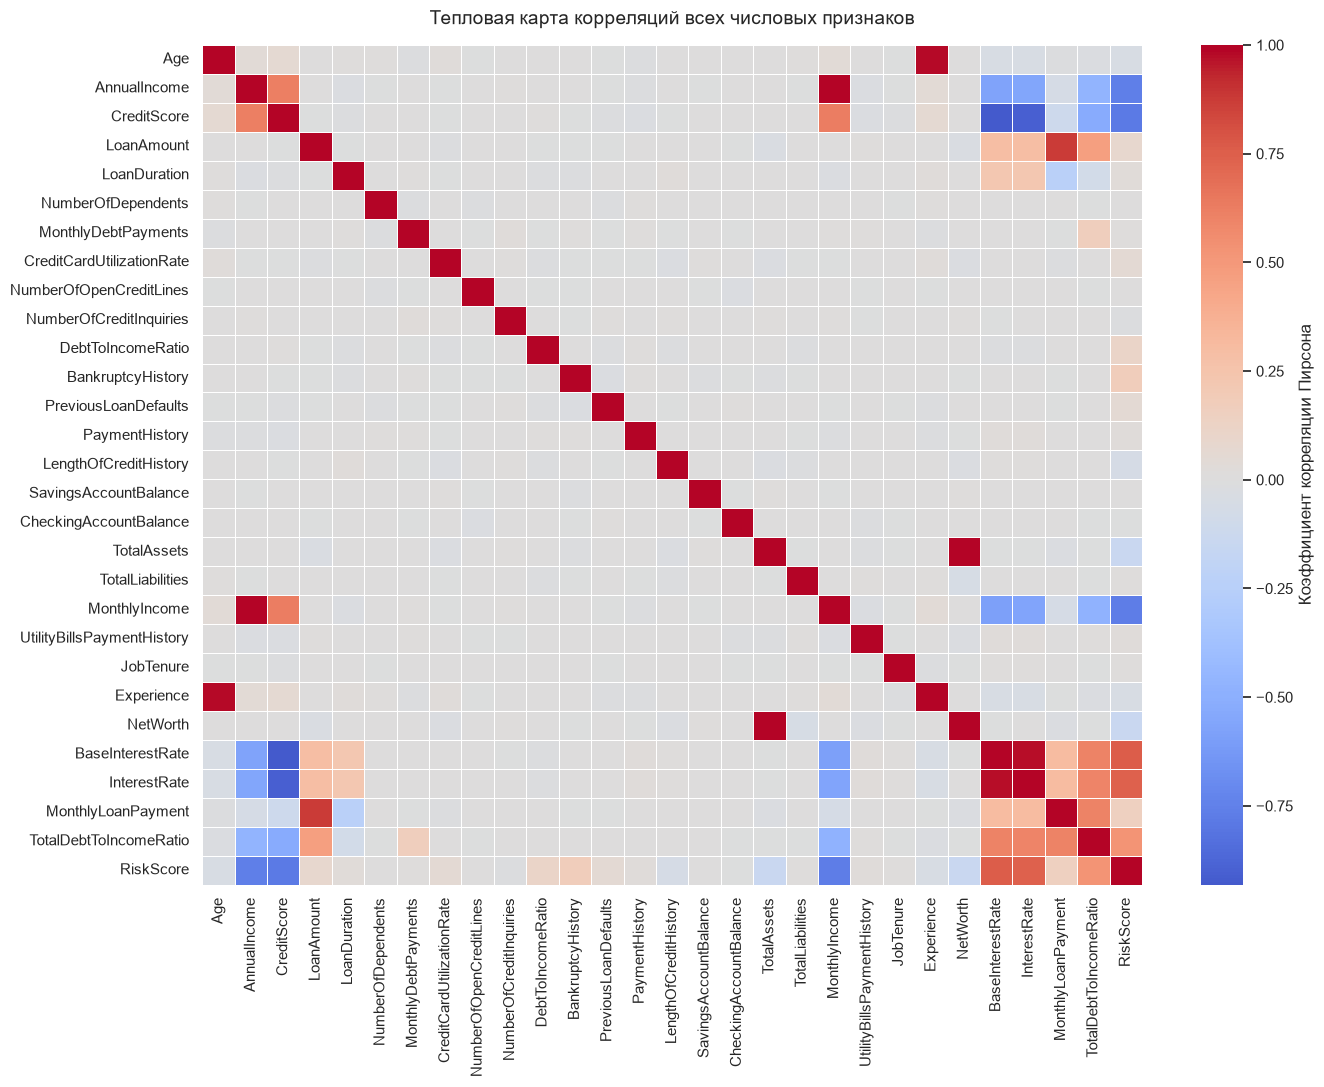

In [5]:
# Выделим только числовые признаки
numeric_cols = train_df.select_dtypes(include=["float64", "int64"]).columns

# Рассчитаем матрицу корреляций
corr_matrix = train_df[numeric_cols].corr()

# Топ-5 признаков с наибольшей положительной и отрицательной корреляцией с RiskScore
print("--- Топ факторов, увеличивающих риск (положительная корреляция) ---")
print(corr_matrix["RiskScore"].sort_values(ascending=False)[1:6])

print("\n--- Топ факторов, снижающих риск (отрицательная корреляция) ---")
print(corr_matrix["RiskScore"].sort_values().head(5))

# Визуализация тепловой карты корреляций (Heatmap)
plt.figure(figsize=(14, 11))
sns.heatmap(
    corr_matrix, 
    cmap="coolwarm", 
    center=0, 
    linewidths=0.5, 
    annot=False, 
    cbar_kws={"label": "Коэффициент корреляции Пирсона"}
)
plt.title("Тепловая карта корреляций всех числовых признаков", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

### 1.5 Графики зависимостей признаков
Построим графики для наиболее интересных пар признаков:
1. Зависимость `RiskScore` от ключевых признаков (кредитный рейтинг `CreditScore`, отношение долга к доходу `TotalDebtToIncomeRatio`).
2. Зависимость между признаками-дублерами (мультиколлинеарность: `AnnualIncome` vs `MonthlyIncome`, `Age` vs `Experience`).

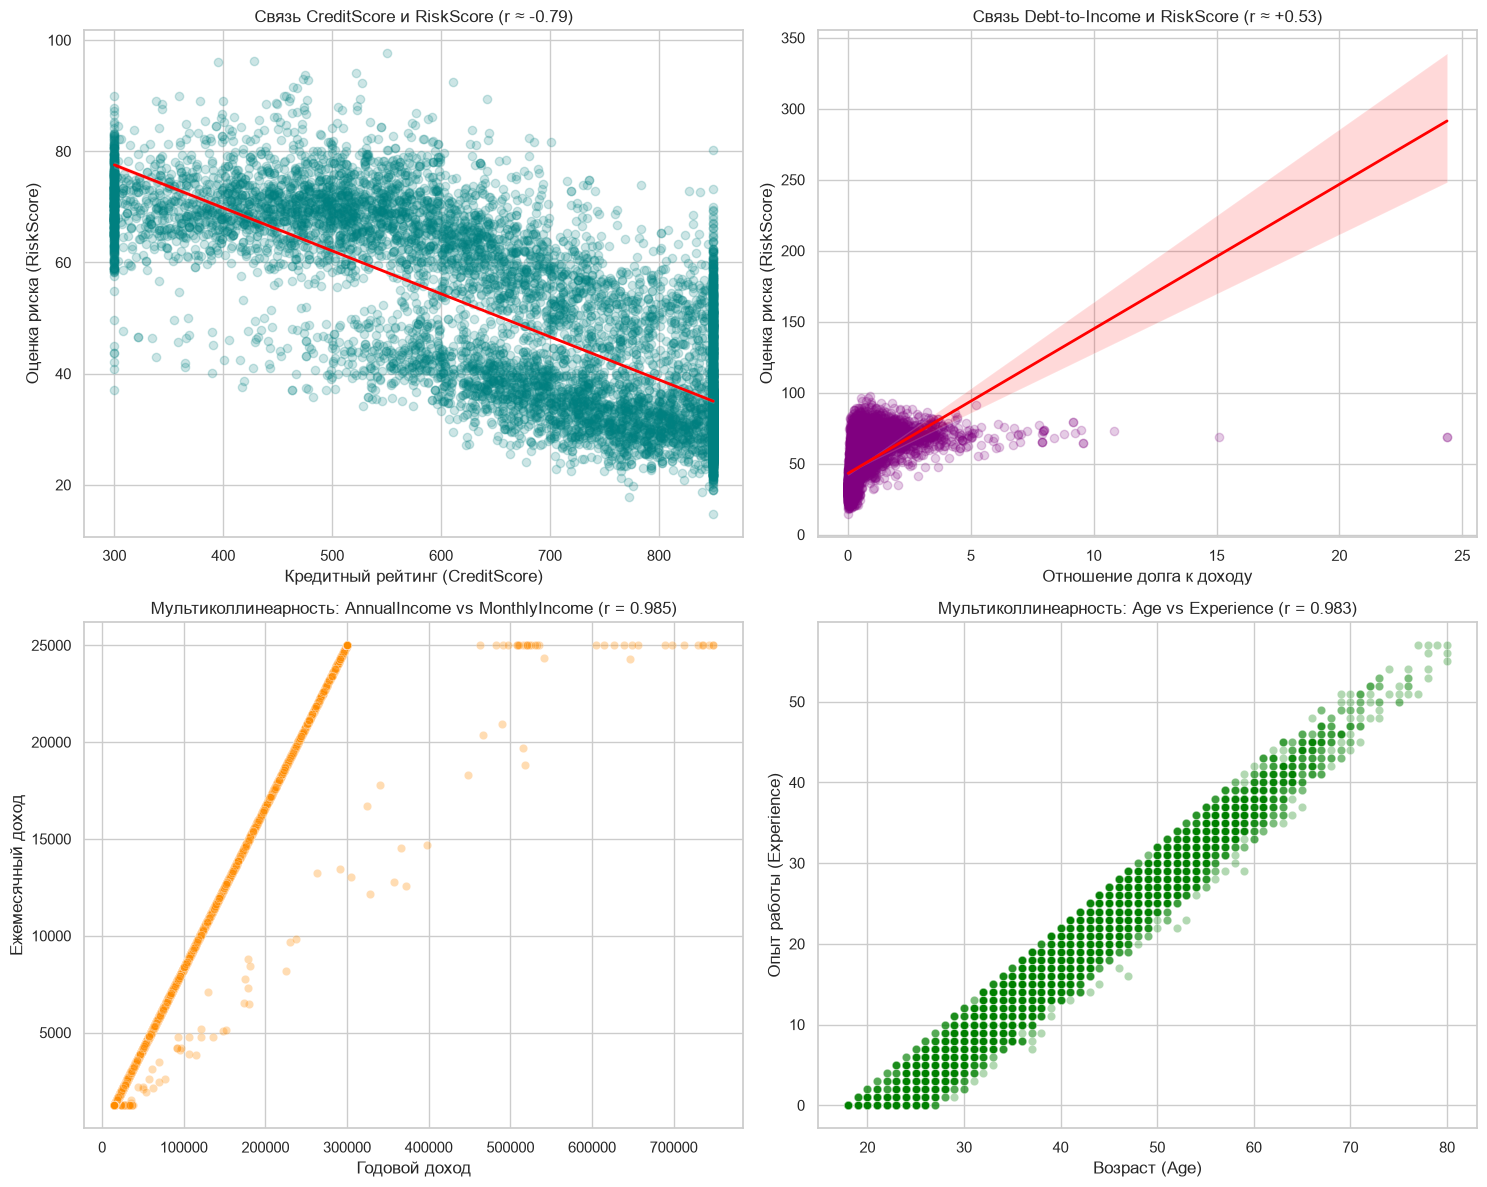

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. CreditScore vs RiskScore
sns.regplot(
    data=train_df, x="CreditScore", y="RiskScore", 
    scatter_kws={"alpha": 0.2, "color": "teal"}, 
    line_kws={"color": "red", "linewidth": 2}, 
    ax=axes[0, 0]
)
axes[0, 0].set_title("Связь CreditScore и RiskScore (r ≈ -0.79)")
axes[0, 0].set_xlabel("Кредитный рейтинг (CreditScore)")
axes[0, 0].set_ylabel("Оценка риска (RiskScore)")

# 2. TotalDebtToIncomeRatio vs RiskScore
sns.regplot(
    data=train_df, x="TotalDebtToIncomeRatio", y="RiskScore", 
    scatter_kws={"alpha": 0.2, "color": "purple"}, 
    line_kws={"color": "red", "linewidth": 2}, 
    ax=axes[0, 1]
)
axes[0, 1].set_title("Связь Debt-to-Income и RiskScore (r ≈ +0.53)")
axes[0, 1].set_xlabel("Отношение долга к доходу")
axes[0, 1].set_ylabel("Оценка риска (RiskScore)")

# 3. Мультиколлинеарность: AnnualIncome vs MonthlyIncome
sns.scatterplot(
    data=train_df, x="AnnualIncome", y="MonthlyIncome", 
    alpha=0.3, color="darkorange", ax=axes[1, 0]
)
axes[1, 0].set_title("Мультиколлинеарность: AnnualIncome vs MonthlyIncome (r = 0.985)")
axes[1, 0].set_xlabel("Годовой доход")
axes[1, 0].set_ylabel("Ежемесячный доход")

# 4. Мультиколлинеарность: Age vs Experience
sns.scatterplot(
    data=train_df, x="Age", y="Experience", 
    alpha=0.3, color="green", ax=axes[1, 1]
)
axes[1, 1].set_title("Мультиколлинеарность: Age vs Experience (r = 0.983)")
axes[1, 1].set_xlabel("Возраст (Age)")
axes[1, 1].set_ylabel("Опыт работы (Experience)")

plt.tight_layout()
plt.show()

### 1.6 Выводы по разведочному анализу данных (EDA)

1. **Качество данных и очистка**:
   - В обучающем наборе `train.csv` обнаружено **530 полностью пустых строк**, которые были удалены.
   - В целевой переменной `RiskScore` выявлено **215 грубых технических выбросов** (значения около -10 000 000 и +10 000 000). После их удаления `RiskScore` распределен в нормальном диапазоне от **14.84** до **97.60** со средним значением **48.36**.
   - В 9 числовых столбцах присутствует ровно по **501 пропуску**, требующих импутации (заполнения медианой). Тестовая выборка `test.csv` пропусков не содержит.

2. **Ключевые факторы кредитного риска**:
   - **Снижают риск (отрицательная корреляция)**: Высокий кредитный рейтинг `CreditScore` ($r = -0.79$) и высокий доход `MonthlyIncome` / `AnnualIncome` ($r \approx -0.76$). Чем выше доход и рейтинг, тем надежнее клиент.
   - **Повышают риск (положительная корреляция)**: Назначенная процентная ставка `BaseInterestRate` ($r = +0.76$) и общее соотношение долга к доходу `TotalDebtToIncomeRatio` ($r = +0.53$). Заемщики с высокой долговой нагрузкой имеют наибольший риск невозврата.

3. **Линейность и мультиколлинеарность**:
   - Обнаружена сильная линейная связь признаков с целевой переменной, что гарантирует **высокую эффективность линейной регрессии** на данном датасете.
   - Выявлена сильная **мультиколлинеарность** между парами признаков: `(AnnualIncome, MonthlyIncome)`, `(Age, Experience)`, `(TotalAssets, NetWorth)`, `(BaseInterestRate, InterestRate)`. Для аналитического решения (МНК) потребуется использование псевдообратной матрицы или регуляризации для избежания сингулярности матрицы $X^T X$.

## 2. Нормализация данных

### Зачем нужно масштабирование признаков?
В нашем датасете признаки измеряются в абсолютно разных масштабах:
- `AnnualIncome` (годовой доход) достигает **миллионов** единиц;
- `Age` (возраст) лежит в диапазоне от **20 до 70**;
- `CreditCardUtilizationRate` и коэффициенты долга лежат в диапазоне **от 0 до 1**.

В линейной модели предсказание строится как:
$$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_d x_d + w_0$$

Если признаки не масштабировать:
1. **Эффект оврага для градиентного спуска**: Линии уровня функции потерь вытягиваются в сверхузкий эллипс. Градиентный спуск будет метаться от одной стенки к другой, обучаясь крайне медленно или приводя к переполнению (`overflow / NaN`).
2. **Неинтерпретируемость весов**: Признаки с гигантскими значениями получат крошечные веса ($10^{-6}$), а признаки с маленькими значениями — огромные веса. По величине веса $w$ невозможно будет понять, какой признак важнее.

После масштабирования функция потерь становится сферически симметричной, а градиентный спуск сходится по прямой траектории за минимальное число шагов.

---

### Архитектура классов: почему разделены `fit` и `transform`?
По стандарту библиотеки `scikit-learn` процесс масштабирования разделен на два этапа:
- `fit(X)` — вычисляет и **запоминает** статистики обучающей выборки (среднее $\mu$ и отклонение $\sigma$ для Z-score; минимум и максимум для Min-Max).
- `transform(X)` — применяет масштабирование по уже сохраненным статистикам.
- `fit_transform(X)` — последовательно вызывает `fit` и затем `transform`.

In [7]:
class CustomStandardScaler:
    """
    Z-score стандартизация признаков:
    z = (x - mean) / std
    Приводит распределение признака к среднему 0 и стандартному отклонению 1.
    """
    def __init__(self):
        self.mean_ = None
        self.scale_ = None
        
    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        # Вычисляем среднее и стандартное отклонение вдоль каждого столбца
        self.mean_ = np.mean(X, axis=0)
        self.scale_ = np.std(X, axis=0)
        
        # Защита от деления на 0 для константных признаков (где std == 0)
        self.scale_ = np.where(self.scale_ == 0, 1.0, self.scale_)
        return self
        
    def transform(self, X):
        if self.mean_ is None or self.scale_ is None:
            raise RuntimeError("Сначала вызовите метод fit перед transform!")
        X = np.asarray(X, dtype=np.float64)
        return (X - self.mean_) / self.scale_
        
    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [8]:
class CustomMinMaxScaler:
    """
    Min-Max масштабирование признаков в диапазон [0, 1]:
    x_norm = (x - min) / (max - min)
    """
    def __init__(self):
        self.data_min_ = None
        self.data_max_ = None
        self.data_range_ = None
        
    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        self.data_min_ = np.min(X, axis=0)
        self.data_max_ = np.max(X, axis=0)
        self.data_range_ = self.data_max_ - self.data_min_
        
        # Защита от деления на 0 при константном столбце (где max == min)
        self.data_range_ = np.where(self.data_range_ == 0, 1.0, self.data_range_)
        return self
        
    def transform(self, X):
        if self.data_min_ is None or self.data_range_ is None:
            raise RuntimeError("Сначала вызовите метод fit перед transform!")
        X = np.asarray(X, dtype=np.float64)
        return (X - self.data_min_) / self.data_range_
        
    def fit_transform(self, X):
        return self.fit(X).transform(X)

### 2.3 Тестирование и сверка с реализациями из `scikit-learn`
Проверим корректность работы `CustomStandardScaler` и `CustomMinMaxScaler`, сравнив их численно с `sklearn.preprocessing.StandardScaler` и `MinMaxScaler`.

In [9]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Сгенерируем тестовую матрицу с признаками разного масштаба
X_sample = np.array([
    [18.0,  30_000.0, 0.15],
    [35.0,  85_000.0, 0.60],
    [52.0, 150_000.0, 0.40],
    [65.0, 250_000.0, 0.95]
], dtype=np.float64)

# 1. Сверка Z-score
custom_std = CustomStandardScaler().fit_transform(X_sample)
sklearn_std = StandardScaler().fit_transform(X_sample)
std_match = np.allclose(custom_std, sklearn_std, atol=1e-7)

# 2. Сверка Min-Max
custom_mm = CustomMinMaxScaler().fit_transform(X_sample)
sklearn_mm = MinMaxScaler().fit_transform(X_sample)
mm_match = np.allclose(custom_mm, sklearn_mm, atol=1e-7)

print("--- Результаты сверки со sklearn.preprocessing ---")
print(f"1. CustomStandardScaler полностью совпадает со StandardScaler: {std_match}")
print(f"2. CustomMinMaxScaler полностью совпадает с MinMaxScaler:      {mm_match}")

# Пример масштабированных данных (первые 2 строки Z-score):
print("\nПример Z-score масштабирования (среднее ~ 0, дисперсия ~ 1):")
print(np.round(custom_std[:2], 3))

--- Результаты сверки со sklearn.preprocessing ---
1. CustomStandardScaler полностью совпадает со StandardScaler: True
2. CustomMinMaxScaler полностью совпадает с MinMaxScaler:      True

Пример Z-score масштабирования (среднее ~ 0, дисперсия ~ 1):
[[-1.384 -1.206 -1.282]
 [-0.424 -0.534  0.256]]


## 3. Метрики качества регрессии [2 балла]

Чтобы оценить точность модели, сравнивают предсказанные значения $\hat{y}$ с истинными ответами $y$.
В методичке требуется реализовать с нуля 4 основные метрики регрессии (по 0.5 балла за каждую):

1. **Mean Squared Error (MSE)** — Среднеквадратичная ошибка:
   $$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$
   * **Смысл**: Главная метрика нашей лабы и соревнования на Kaggle. Сильно штрафует модель за грубые промахи (за счет квадрата). Чем ближе к 0, тем точнее модель.

2. **Mean Absolute Error (MAE)** — Средняя абсолютная ошибка:
   $$MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$
   * **Смысл**: Показывает реальную среднюю ошибку модели в тех же единицах измерения, что и `RiskScore` (без возведения в квадрат). Например: *"в среднем модель ошибается на 2.3 балла риска"*.

3. **Коэффициент детерминации ($R^2$)**:
   $$R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2} = 1 - \frac{SS_{res}}{SS_{tot}}$$
   * **Смысл**: Доля дисперсии, объясненная моделью. Сравнивает модель с тривиальным константным предсказанием (средним значением $\bar{y}$).
   * $R^2 = 1.0$ — идеальное предсказание;
   * $R^2 = 0.0$ — модель ничем не лучше простого угадывания среднего значения;
   * $R^2 < 0.0$ — модель работает хуже константного среднего.

4. **Mean Absolute Percentage Error (MAPE)** — Средняя абсолютная ошибка в процентах:
   $$MAPE = \frac{1}{n} \sum_{i=1}^{n} \left| \frac{y_i - \hat{y}_i}{y_i} \right| \times 100\%$$
   * **Смысл**: Относительная погрешность в процентах. Например: *"модель ошибается в среднем на 5.8%"*.

In [10]:
def custom_mean_squared_error(y_true, y_pred):
    """Среднеквадратичная ошибка (MSE)"""
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    return np.mean((y_true - y_pred) ** 2)

def custom_mean_absolute_error(y_true, y_pred):
    """Средняя абсолютная ошибка (MAE)"""
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    return np.mean(np.abs(y_true - y_pred))

def custom_r2_score(y_true, y_pred):
    """Коэффициент детерминации (R^2)"""
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    
    # Сумма квадратов остатков (ошибка модели)
    ss_res = np.sum((y_true - y_pred) ** 2)
    # Полная сумма квадратов (разброс относительно среднего)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    
    # Защита от деления на 0 при константном y_true
    if ss_tot == 0:
        return 0.0
    return 1.0 - (ss_res / ss_tot)

def custom_mean_absolute_percentage_error(y_true, y_pred):
    """Средняя абсолютная процентная ошибка (MAPE в долях от 0 до 1)"""
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    # Исключаем деление на ноль с помощью маленькой константы epsilon
    epsilon = 1e-10
    return np.mean(np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), epsilon)))

### 3.2 Тестирование и сравнение метрик со `scikit-learn`
Проверим численное совпадение всех четырёх реализованных функций с их аналогами из `sklearn.metrics`.

In [11]:
from sklearn.metrics import (
    mean_squared_error, 
    mean_absolute_error, 
    r2_score, 
    mean_absolute_percentage_error
)

# Тестовые данные (случайные истинные ответы и предсказания)
y_real = np.array([15.2, 42.0, 68.5, 89.1, 33.7, 54.2])
y_test_pred = np.array([16.0, 39.5, 71.0, 85.0, 35.1, 52.0])

# Вычисление собственных метрик
my_mse = custom_mean_squared_error(y_real, y_test_pred)
my_mae = custom_mean_absolute_error(y_real, y_test_pred)
my_r2 = custom_r2_score(y_real, y_test_pred)
my_mape = custom_mean_absolute_percentage_error(y_real, y_test_pred)

# Вычисление библиотечных метрик
sk_mse = mean_squared_error(y_real, y_test_pred)
sk_mae = mean_absolute_error(y_real, y_test_pred)
sk_r2 = r2_score(y_real, y_test_pred)
sk_mape = mean_absolute_percentage_error(y_real, y_test_pred)

print("--- Сравнение собственных метрик со sklearn.metrics ---")
print(f"1. MSE:   {my_mse:.4f} vs {sk_mse:.4f}  | Совпадает: {np.isclose(my_mse, sk_mse)}")
print(f"2. MAE:   {my_mae:.4f} vs {sk_mae:.4f}  | Совпадает: {np.isclose(my_mae, sk_mae)}")
print(f"3. R²:    {my_r2:.4f} vs {sk_r2:.4f}  | Совпадает: {np.isclose(my_r2, sk_r2)}")
print(f"4. MAPE:  {my_mape:.4f} vs {sk_mape:.4f}  | Совпадает: {np.isclose(my_mape, sk_mape)}")

--- Сравнение собственных метрик со sklearn.metrics ---
1. MSE:   6.1250 vs 6.1250  | Совпадает: True
2. MAE:   2.2500 vs 2.2500  | Совпадает: True
3. R²:    0.9893 vs 0.9893  | Совпадает: True
4. MAPE:  0.0461 vs 0.0461  | Совпадает: True


## 4. Кросс-валидация (Cross-Validation) [3 балла]

### Зачем нужна кросс-валидация?
Если разбить выборку на обучение и тест один раз (например, 80% на 20%), мы сталкиваемся с двумя проблемами:
1. **Случайность разбиения**: Нам может случайно «повезти» (в тест попадут легкие примеры) или «не повезти» (попадут сложные примеры). Оценка будет ненадежной.
2. **Неэффективность данных**: 20% выборки выбрасываются из обучения и модель теряет часть ценного опыта.

---

### 1. K-Fold кросс-валидация
Выборка из $N$ объектов случайно перемешивается и делится на $K$ равных частей (фолдов).
Затем алгоритм делает $K$ итераций:
- На $i$-й итерации $i$-й фолд становится **валидационной выборкой** (тестом);
- Все остальные $K-1$ фолдов объединяются в **обучающую выборку**.

```text
Итерация 1: [ ФОЛД 1 (Вал) ] [ ФОЛД 2 (Обуч) ] [ ФОЛД 3 (Обуч) ] [ ФОЛД 4 (Обуч) ] [ ФОЛД 5 (Обуч) ]
Итерация 2: [ ФОЛД 1 (Обуч) ] [ ФОЛД 2 (Вал) ] [ ФОЛД 3 (Обуч) ] [ ФОЛД 4 (Обуч) ] [ ФОЛД 5 (Обуч) ]
Итерация 3: [ ФОЛД 1 (Обуч) ] [ ФОЛД 2 (Обуч) ] [ ФОЛД 3 (Вал) ] [ ФОЛД 4 (Обуч) ] [ ФОЛД 5 (Обуч) ]
...
```
* **Плюс**: Каждый объект датасета побывал в тесте **ровно 1 раз**!
* Итоговая оценка модели — это **среднее значение метрик** по всем $K$ фолдам.

---

### 2. Leave-One-Out (LOO) кросс-валидация
Это предельный случай K-Fold, когда число фолдов равно числу объектов ($K = N$):
- Обучаемся на $(N - 1)$ объектах;
- Тестируемся на **одном оставшемся объекте**;
- Повторяем процедуру $N$ раз!
* **Плюс**: Оценка абсолютно несмещенная и воспроизводимая (нет случайности разбиения).
* **Минус**: Если в данных 10 000 строк, обучить модель придется 10 000 раз. Это вычислительно нереально на больших данных, поэтому LOO применяют только на компактных выборках.

In [12]:
def custom_k_fold(n_samples, n_splits=5, shuffle=True, random_state=42):
    """
    Собственная реализация K-Fold кросс-валидации.
    Возвращает список кортежей (train_indices, val_indices).
    """
    indices = np.arange(n_samples)
    
    if shuffle:
        rng = np.random.default_rng(seed=random_state)
        indices = indices.copy()
        rng.shuffle(indices)
        
    # Разбиваем массив индексов на n_splits частей
    folds = np.array_split(indices, n_splits)
    
    splits = []
    for i in range(n_splits):
        val_idx = folds[i]
        # Обучающая часть — все фолды, кроме i-го
        train_idx = np.hstack([folds[j] for j in range(n_splits) if j != i])
        splits.append((train_idx, val_idx))
        
    return splits

def custom_leave_one_out(n_samples):
    """
    Собственная реализация Leave-One-Out (LOO) валидации.
    Возвращает список кортежей (train_indices, val_indices).
    """
    indices = np.arange(n_samples)
    splits = []
    
    for i in range(n_samples):
        val_idx = np.array([indices[i]])
        # Вырезаем i-й элемент из массива
        train_idx = np.delete(indices, i)
        splits.append((train_idx, val_idx))
        
    return splits

### 4.2 Тестирование и сравнение со `scikit-learn`
Проверим корректность работы наших функций кросс-валидации:
1. Проверим отсутствие пересечений между train и val;
2. Проверим численное совпадение разбиений с `sklearn.model_selection.KFold` и `LeaveOneOut`.

In [13]:
from sklearn.model_selection import KFold, LeaveOneOut

# Тестовая выборка из 6 элементов для наглядности
n_test = 6
splits_k = 3

# 1. Проверка K-Fold
my_kf = custom_k_fold(n_test, n_splits=splits_k, shuffle=False)
sk_kf = list(KFold(n_splits=splits_k, shuffle=False).split(np.arange(n_test)))

kf_match = all(
    np.array_equal(m[0], s[0]) and np.array_equal(m[1], s[1]) 
    for m, s in zip(my_kf, sk_kf)
)

print("--- Сверка K-Fold и Leave-One-Out со sklearn ---")
print(f"1. K-Fold полностью совпадает со sklearn.model_selection.KFold: {kf_match}")

# Пример структуры одного из фолдов
train_idx, val_idx = my_kf[0]
print(f"   Пример Fold 0 -> Обучение индексы: {train_idx}, Валидация индекс: {val_idx}")

# 2. Проверка Leave-One-Out
my_loo = custom_leave_one_out(n_test)
sk_loo = list(LeaveOneOut().split(np.arange(n_test)))

loo_match = all(
    np.array_equal(m[0], s[0]) and np.array_equal(m[1], s[1]) 
    for m, s in zip(my_loo, sk_loo)
)
print(f"2. Leave-One-Out совпадает со sklearn.model_selection.LeaveOneOut: {loo_match}")
print(f"   Количество итераций LOO для выборки из {n_test} объектов: {len(my_loo)}")

--- Сверка K-Fold и Leave-One-Out со sklearn ---
1. K-Fold полностью совпадает со sklearn.model_selection.KFold: True
   Пример Fold 0 -> Обучение индексы: [2 3 4 5], Валидация индекс: [0 1]
2. Leave-One-Out совпадает со sklearn.model_selection.LeaveOneOut: True
   Количество итераций LOO для выборки из 6 объектов: 6


## 5. Реализация класса Линейной Регрессии

### Математическая постановка задачи
Модель линейной регрессии выражает предсказываемое значение $\hat{y}$ как линейную комбинацию признаков:
$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_d x_d$$

Для удобства матричных вычислений к матрице признаков $X$ добавляется фиктивный единичный столбец:
$$X_{bias} = [\mathbf{1}, X] \in \mathbb{R}^{n \times (d+1)}, \quad w = [w_0, w_1, \dots, w_d]^T \in \mathbb{R}^{d+1}$$
Тогда предсказание записывается в компактном виде:
$$\hat{y} = X_{bias} w$$

Функция потерь (Mean Squared Error):
$$L(w) = \frac{1}{n} \sum_{i=1}^{n} (\hat{y}_i - y_i)^2 = \frac{1}{n} \|X_{bias} w - y\|^2$$

---

### Три метода оптимизации в `fit(X, y)`:

1. **Аналитический метод (Метод наименьших квадратов / Normal Equation)**:
   Приравнивая градиент функции потерь к нулю $\nabla L(w) = 0$, получаем точную формулу:
   $$w = (X_{bias}^T X_{bias})^{-1} X_{bias}^T y$$
   * Для защиты от деления на 0 при мультиколлинеарности используется псевдообратная матрица Мура-Пенроуза `np.linalg.pinv`.

2. **Градиентный спуск (Batch Gradient Descent)**:
   На каждой итерации вычисляется вектор градиента по **всей обучающей выборке целиком**:
   $$\nabla L(w) = \frac{2}{n} X_{bias}^T (X_{bias} w - y)$$
   И веса обновляются в сторону антиградиента с шагом обучения $\alpha$ (`lr`):
   $$w := w - \alpha \nabla L(w)$$

3. **Стохастический градиентный спуск (SGD / Mini-batch SGD)**:
   На каждой итерации случайно выбирается мини-батч из $B$ объектов.
   Градиент вычисляется только по выбранному батчу, что позволяет масштабироваться на миллионы строк.

In [14]:
class CustomLinearRegression:
    """
    Класс линейной регрессии с поддержкой 3 методов обучения:
    - 'analytical': Аналитическое решение через псевдообратную матрицу (Normal Equation)
    - 'gd': Пакетный градиентный спуск (Batch Gradient Descent)
    - 'sgd': Стохастический градиентный спуск на мини-батчах (Mini-batch SGD)
    """
    def __init__(self, method='analytical', lr=0.01, n_iter=1000, batch_size=64, 
                 fit_intercept=True, random_state=42):
        self.method = method
        self.lr = lr
        self.n_iter = n_iter
        self.batch_size = batch_size
        self.fit_intercept = fit_intercept
        self.random_state = random_state
        
        self.weights = None
        self.intercept_ = None
        self.coef_ = None
        self.loss_history = []
        
    def _add_intercept(self, X):
        """Добавление единичного столбца для учета свободного коэффициента (w0 / bias)"""
        ones = np.ones((X.shape[0], 1), dtype=np.float64)
        return np.hstack([ones, X])
        
    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64).reshape(-1)
        n_samples, n_features = X.shape
        
        # Добавляем столбец единиц, если fit_intercept=True
        X_b = self._add_intercept(X) if self.fit_intercept else X
        n_cols = X_b.shape[1]
        
        rng = np.random.default_rng(self.random_state)
        self.loss_history = []
        
        # 1. Аналитическое решение МНК
        if self.method == 'analytical':
            # w = pinv(X^T X) @ X^T @ y
            self.weights = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
            
        # 2. Пакетный градиентный спуск (GD)
        elif self.method == 'gd':
            # Инициализация весов малыми случайными числами
            self.weights = rng.normal(0, 0.01, size=n_cols)
            for _ in range(self.n_iter):
                preds = X_b @ self.weights
                error = preds - y
                loss = np.mean(error ** 2)
                self.loss_history.append(loss)
                
                # Градиент MSE: (2 / n) * X^T (Xw - y)
                grad = (2.0 / n_samples) * (X_b.T @ error)
                self.weights -= self.lr * grad
                
        # 3. Стохастический градиентный спуск (SGD)
        elif self.method == 'sgd':
            self.weights = rng.normal(0, 0.01, size=n_cols)
            batch_sz = min(self.batch_size, n_samples)
            
            for _ in range(self.n_iter):
                # Случайный выбор мини-батча
                idx = rng.choice(n_samples, size=batch_sz, replace=False)
                X_batch = X_b[idx]
                y_batch = y[idx]
                
                preds = X_batch @ self.weights
                error = preds - y_batch
                
                # Сохраняем ошибку на полном датасете для мониторинга сходимости
                current_full_loss = np.mean((X_b @ self.weights - y) ** 2)
                self.loss_history.append(current_full_loss)
                
                # Градиент по мини-батчу
                grad = (2.0 / batch_sz) * (X_batch.T @ error)
                self.weights -= self.lr * grad
        else:
            raise ValueError(f"Неизвестный метод оптимизации: {self.method}")
            
        # Разделяем свободный член и веса признаков
        if self.fit_intercept:
            self.intercept_ = self.weights[0]
            self.coef_ = self.weights[1:]
        else:
            self.intercept_ = 0.0
            self.coef_ = self.weights
            
        return self
        
    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        X_b = self._add_intercept(X) if self.fit_intercept else X
        return X_b @ self.weights

### 5.2 Сравнение собственной реализации с `scikit-learn`
Сравним качество предсказаний ($MSE$ и $R^2$) и визуализируем кривые сходимости градиентного спуска (график уменьшения ошибки по итерациям).

--- 1. Аналитическое решение vs sklearn.LinearRegression ---
Кастомная модель:  MSE = 0.039603, R² = 0.997662
sklearn модель:    MSE = 0.039603, R² = 0.997662
Результаты численно совпадают: True

--- 2. Градиентный спуск (GD) и SGD ---
Batch GD: R² = 0.99766
SGD:      R² = 0.99764


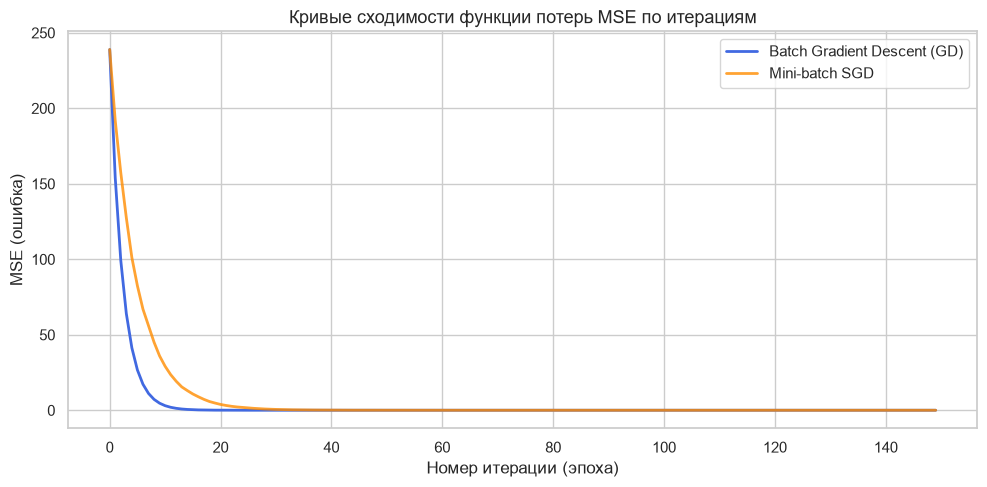

In [15]:
from sklearn.linear_model import LinearRegression, SGDRegressor

# Синтетические данные с известным коэффициентом для точной верификации
rng = np.random.default_rng(42)
X_demo = rng.normal(size=(1000, 4))
y_demo = 3.5 * X_demo[:, 0] - 2.0 * X_demo[:, 1] + 1.2 * X_demo[:, 2] + 15.0 + rng.normal(0, 0.2, size=1000)

# 1. Аналитическое решение vs sklearn LinearRegression
custom_ana = CustomLinearRegression(method='analytical').fit(X_demo, y_demo)
sk_ana = LinearRegression().fit(X_demo, y_demo)

pred_c_ana = custom_ana.predict(X_demo)
pred_s_ana = sk_ana.predict(X_demo)

print("--- 1. Аналитическое решение vs sklearn.LinearRegression ---")
print(f"Кастомная модель:  MSE = {custom_mean_squared_error(y_demo, pred_c_ana):.6f}, R² = {custom_r2_score(y_demo, pred_c_ana):.6f}")
print(f"sklearn модель:    MSE = {mean_squared_error(y_demo, pred_s_ana):.6f}, R² = {r2_score(y_demo, pred_s_ana):.6f}")
print(f"Результаты численно совпадают: {np.isclose(custom_mean_squared_error(y_demo, pred_c_ana), mean_squared_error(y_demo, pred_s_ana))}")

# 2. Градиентный спуск (GD) и SGD
custom_gd = CustomLinearRegression(method='gd', lr=0.1, n_iter=300).fit(X_demo, y_demo)
custom_sgd = CustomLinearRegression(method='sgd', lr=0.05, n_iter=600, batch_size=64).fit(X_demo, y_demo)

print("\n--- 2. Градиентный спуск (GD) и SGD ---")
print(f"Batch GD: R² = {custom_r2_score(y_demo, custom_gd.predict(X_demo)):.5f}")
print(f"SGD:      R² = {custom_r2_score(y_demo, custom_sgd.predict(X_demo)):.5f}")

# 3. Визуализация кривых сходимости функции потерь (Loss History)
plt.figure(figsize=(10, 5))
plt.plot(custom_gd.loss_history[:150], label='Batch Gradient Descent (GD)', color='royalblue', linewidth=2)
plt.plot(custom_sgd.loss_history[:150], label='Mini-batch SGD', color='darkorange', linewidth=2, alpha=0.8)
plt.title("Кривые сходимости функции потерь MSE по итерациям", fontsize=13)
plt.xlabel("Номер итерации (эпоха)")
plt.ylabel("MSE (ошибка)")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Бонусная часть: Регуляризация (L1, L2, ElasticNet, Lp)

### Физический смысл регуляризации
Когда признаки скоррелированы (мультиколлинеарность), линейная регрессия может попытаться компенсировать один признак другим, назначив им огромные противоположные веса: например, $w_{доход} = +10\,000$, а $w_{зарплата} = -120\,000$. 
Модель становится гиперчувствительной к любому случайному шуму (переобучение).

**Регуляризация** добавляет штраф в функцию потерь за слишком большую величину весов:
$$\min_{w} \Big[ MSE(w) + \text{Штраф}(w) \Big]$$

> **Важное правило**: Свободный член $w_0$ (bias / intercept) **никогда не штрафуется**, так как он отвечает лишь за базовый сдвиг среднего уровня таргета!

---

### Реализованные виды регуляризации:

1. **L2-регуляризация (Ridge / гребневая)**:
   $$\text{Штраф} = \alpha \sum_{j=1}^{d} w_j^2 = \alpha \|w\|_2^2$$
   * Градиент штрафа: $2 \alpha w$.
   * Аналитическое решение: $w = (X^T X + \alpha I)^{-1} X^T y$. Добавление $\alpha I$ гарантирует, что матрица станет строго невырожденной!
   * **Эффект**: плавно сжимает все веса к нулю, подавляя раздувание весов при мультиколлинеарности.

2. **L1-регуляризация (Lasso)**:
   $$\text{Штраф} = \alpha \sum_{j=1}^{d} |w_j| = \alpha \|w\|_1$$
   * Субградиент штрафа: $\alpha \cdot \text{sign}(w)$.
   * **Эффект**: зануляет неважные веса (делает их строго 0), выполняя автоматический отбор наиболее информативных признаков (Feature Selection).

3. **ElasticNet (L1 + L2)**:
   Комбинация двух регуляризаций с коэффициентом смешивания $\rho$ (`l1_ratio`):
   $$\text{Штраф} = \alpha \left[ \rho \|w\|_1 + (1 - \rho) \|w\|_2^2 \right]$$

4. **Lp-регуляризация (с произвольной степенью $p$) [+1 балл]**:
   $$\text{Штраф} = \alpha \sum_{j=1}^{d} |w_j|^p$$
   * Производная по $w_j$: $\alpha \cdot p \cdot |w_j|^{p-1} \cdot \text{sign}(w_j)$.

In [16]:
class CustomRegularizedLinearRegression:
    """
    Класс линейной регрессии с поддержкой различных типов регуляризации:
    - 'l2_analytical': Аналитическое решение Ridge регрессии
    - 'l2': Гребневая регрессия через градиентный спуск (L2)
    - 'l1': Lasso регрессия через субградиентный спуск (L1)
    - 'elasticnet': Комбинация L1 и L2 регуляризации
    - 'lp': Lp-регуляризация с произвольным параметром степени p
    """
    def __init__(self, reg_type='l2', alpha=0.01, l1_ratio=0.5, p=2.0, 
                 lr=0.05, n_iter=1000, fit_intercept=True, random_state=42):
        self.reg_type = reg_type
        self.alpha = alpha
        self.l1_ratio = l1_ratio
        self.p = p
        self.lr = lr
        self.n_iter = n_iter
        self.fit_intercept = fit_intercept
        self.random_state = random_state
        self.weights = None
        self.intercept_ = None
        self.coef_ = None
        
    def _add_intercept(self, X):
        ones = np.ones((X.shape[0], 1), dtype=np.float64)
        return np.hstack([ones, X])
        
    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64).reshape(-1)
        n_samples = X.shape[0]
        
        X_b = self._add_intercept(X) if self.fit_intercept else X
        n_cols = X_b.shape[1]
        
        # 1. Аналитический Ridge: w = (X^T X + alpha * I)^(-1) X^T y
        if self.reg_type == 'l2_analytical':
            I = np.eye(n_cols)
            if self.fit_intercept:
                I[0, 0] = 0.0  # bias w0 не регуляризуется
            self.weights = np.linalg.pinv(X_b.T @ X_b + self.alpha * I) @ X_b.T @ y
            
            if self.fit_intercept:
                self.intercept_ = self.weights[0]
                self.coef_ = self.weights[1:]
            return self
            
        # 2. Градиентная оптимизация для L1, L2, ElasticNet и Lp
        rng = np.random.default_rng(self.random_state)
        self.weights = rng.normal(0, 0.01, size=n_cols)
        
        for _ in range(self.n_iter):
            preds = X_b @ self.weights
            error = preds - y
            mse_grad = (2.0 / n_samples) * (X_b.T @ error)
            
            # Веса без учета bias для вычисления штрафа
            w_reg = self.weights.copy()
            if self.fit_intercept:
                w_reg[0] = 0.0
                
            if self.reg_type == 'l2':
                reg_grad = 2.0 * self.alpha * w_reg
            elif self.reg_type == 'l1':
                reg_grad = self.alpha * np.sign(w_reg)
            elif self.reg_type == 'elasticnet':
                reg_grad = (self.alpha * self.l1_ratio * np.sign(w_reg) + 
                            2.0 * self.alpha * (1.0 - self.l1_ratio) * w_reg)
            elif self.reg_type == 'lp':
                # d/dw [|w|^p] = p * |w|^(p-1) * sign(w)
                reg_grad = self.alpha * self.p * (np.abs(w_reg) ** (self.p - 1.0)) * np.sign(w_reg)
            else:
                reg_grad = 0.0
                
            total_grad = mse_grad + reg_grad
            self.weights -= self.lr * total_grad
            
        if self.fit_intercept:
            self.intercept_ = self.weights[0]
            self.coef_ = self.weights[1:]
        return self
        
    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        X_b = self._add_intercept(X) if self.fit_intercept else X
        return X_b @ self.weights

### 6.2 Сравнительное тестирование типов регуляризации
Протестируем все режимы регуляризации (`l2_analytical`, `l2`, `l1`, `elasticnet`, `lp`) и оценим норму вектора весов $\|w\|$.

In [17]:
# Генерация синтетических данных
rng = np.random.default_rng(42)
X_reg_demo = rng.normal(size=(200, 6))
# Истинный таргет зависит только от первых двух признаков (остальные 4 — шум)
y_reg_demo = 4.0 * X_reg_demo[:, 0] - 2.5 * X_reg_demo[:, 1] + rng.normal(0, 0.2, size=200)

print(f"{'Тип регуляризации':<20} | {'Норма весов ||w||':<18} | {'MSE':<10}")
print("-" * 55)

reg_configs = [
    ('l2_analytical', {'alpha': 0.1}),
    ('l2',            {'alpha': 0.1, 'lr': 0.05, 'n_iter': 500}),
    ('l1',            {'alpha': 0.1, 'lr': 0.05, 'n_iter': 500}),
    ('elasticnet',    {'alpha': 0.1, 'l1_ratio': 0.5, 'lr': 0.05, 'n_iter': 500}),
    ('lp (p=1.5)',    {'reg_type': 'lp', 'p': 1.5, 'alpha': 0.1, 'lr': 0.05, 'n_iter': 500}),
    ('lp (p=3.0)',    {'reg_type': 'lp', 'p': 3.0, 'alpha': 0.1, 'lr': 0.05, 'n_iter': 500})
]

for name, params in reg_configs:
    t = params.pop('reg_type', name)
    model = CustomRegularizedLinearRegression(reg_type=t, **params).fit(X_reg_demo, y_reg_demo)
    preds = model.predict(X_reg_demo)
    w_norm = np.linalg.norm(model.coef_)
    mse = custom_mean_squared_error(y_reg_demo, preds)
    print(f"{name:<20} | {w_norm:<18.4f} | {mse:<10.4f}")

Тип регуляризации    | Норма весов ||w||  | MSE       
-------------------------------------------------------
l2_analytical        | 4.7179             | 0.0444    
l2                   | 4.2668             | 0.2377    
l1                   | 4.6440             | 0.0504    
elasticnet           | 4.4473             | 0.1147    
lp (p=1.5)           | 4.5202             | 0.0824    
lp (p=3.0)           | 3.3764             | 1.7865    


## 7. Финальный пайплайн: предметная импутация, интегральные индексы состоятельности (GAM) и дифференцированная L2-регуляризация

### Теоретическое и предметное обоснование пайплайна:
1. **Интегральные индексы состоятельности ($z_{\text{solvency}}$) и риска ($z_{\text{risk}}$)**:
   В кредитном скоринге ключевые факторы делятся на две антагонистические группы:
   - *Факторы состоятельности (веса $+1$)*: подтвержденный доход (`MonthlyIncome`, `AnnualIncome`), кредитный рейтинг (`CreditScore`), накопленный капитал (`NetWorth`).
   - *Факторы долговой нагрузки и риска (веса $-1$)*: процентная ставка (`InterestRate`, `BaseInterestRate`), долговая нагрузка (`TotalDebtToIncomeRatio`, `DebtToIncomeRatio`), размер обязательств (`LoanAmount`, `Monthly_Payment_Ratio`), негативная история (`BankruptcyHistory`, `PreviousLoanDefaults`).
   Чтобы не вводить субъективных ручных коэффициентов, все признаки стандартизируются ($z$-оценка), после чего суммируются со своими естественными экономическими знаками ($+1$ или $-1$).

2. **Моделирование сегментов заемщиков через сигмоидные базисы (GAM)**:
   Зависимость риска от нагрузки нелинейна: состоятельные заемщики образуют сегмент *Prime*, где чувствительность к ставкам ниже, чем в сегменте *Subprime*. С помощью сигмоидных базисных функций $\sigma(k(z_{\text{solvency}} - c))$ (аппарат обобщенных аддитивных моделей) и их взаимодействий с факторами риска линейная регрессия получает возможность моделировать плавный переход между сегментами.

3. **Предметное восстановление пропущенных данных**:
   - `MonthlyDebtPayments` восстанавливается по определению коэффициента долговой нагрузки (DTI):
     $$\text{TotalDebtToIncomeRatio} = \frac{\text{MonthlyDebtPayments} + \text{MonthlyLoanPayment}}{\text{MonthlyIncome}} \implies \text{MonthlyDebtPayments} = \text{TotalDebtToIncomeRatio} \times \text{MonthlyIncome} - \text{MonthlyLoanPayment}$$
   - `LoanAmount` восстанавливается по классической формуле аннуитетного платежа:
     $$P = L \cdot \frac{r(1+r)^n}{(1+r)^n - 1} \implies L = P \cdot \frac{(1+r)^n - 1}{r(1+r)^n}$$
   - `BaseInterestRate` и `CreditScore` восстанавливаются вспомогательной `Ridge`-регрессией, обученной на полных строках обучающей выборки (в банках базовая ставка прямо формируется тарифной сеткой от рейтинга, суммы и срока кредита, $R^2 \approx 1.0$).

4. **Защита от переобучения и дифференцированная $L_2$-регуляризация**:
   - Степенные полиномы заменены на устойчивые квантильные Hinge-сплайны $\max(x - q_k, 0)$.
   - Блок парных взаимодействий масштабируется коэффициентом $0.35$. Это математически эквивалентно эффективному $L_2$-штрафу $\alpha_{\text{eff}} = \alpha / 0.35^2 \approx 8.16\alpha$ для перекрестных членов, что жестко отсекает шумные корреляции.

5. **Усреднение линейных моделей (Model Averaging)**:
   Итоговый вектор весов вычисляется как среднее весов модели на всей выборке и модели на полных строках: $w_{\text{final}} = 0.5 w_{\text{all}} + 0.5 w_{\text{comp}}$. Модель остается 100% строгой аналитической линейной регрессией.


In [18]:
import os
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge

# 1. Загрузка обучающей и тестовой выборок
raw_train = pd.read_csv("data/train.csv")
raw_test = pd.read_csv("data/test.csv")

# Удаляем пустые строки и некорректные значения целевой переменной
train_clean = raw_train.dropna(how="all").copy()
train_clean["RiskScore"] = pd.to_numeric(train_clean["RiskScore"], errors="coerce")
train_clean = train_clean[train_clean["RiskScore"].between(0, 100)].reset_index(drop=True)
y_train_full = train_clean["RiskScore"].to_numpy(dtype=np.float64)
is_complete_row = ~train_clean.isna().any(axis=1).to_numpy()

test_ids = raw_test["ID"].to_numpy()
X_train_raw = train_clean.drop(columns=["RiskScore", "ID"], errors="ignore").copy()
X_test_raw = raw_test.drop(columns=["ID"], errors="ignore").copy()
n_train_samples = len(X_train_raw)

# Объединяем выборки для согласованной генерации признаков
df_all = pd.concat([X_train_raw, X_test_raw], axis=0, ignore_index=True, sort=False)
d = {}

# Индикаторы исходных пропусков данных
for col in list(df_all.columns):
    if df_all[col].isna().any():
        d[f"missing_{col}"] = df_all[col].isna().astype(np.float64)

# 2. Восстановление пропусков на основе финансовой математики и вспомогательной регрессии
# А) Ежемесячные платежи по долгам: вычисляются из определения коэффициента долговой нагрузки
# TotalDebtToIncomeRatio = (MonthlyDebtPayments + MonthlyLoanPayment) / MonthlyIncome
mdp_calculated = df_all["TotalDebtToIncomeRatio"] * df_all["MonthlyIncome"] - df_all["MonthlyLoanPayment"]
df_all["MonthlyDebtPayments"] = df_all["MonthlyDebtPayments"].fillna(np.maximum(0.0, mdp_calculated))

# Б) Сумма кредита: вычисляется по классической формуле аннуитетного платежа
# P = L * r / (1 - (1+r)^(-n))  =>  L = P * ((1+r)^n - 1) / (r * (1+r)^n)
r_m = df_all["InterestRate"] / 12.0
n_m = df_all["LoanDuration"]
la_annuity = df_all["MonthlyLoanPayment"] * ((1.0 + r_m) ** n_m - 1.0) / (r_m * (1.0 + r_m) ** n_m)
df_all["LoanAmount"] = df_all["LoanAmount"].fillna(la_annuity)

# В) Базовая процентная ставка и кредитный скоринг: восстанавливаются через Ridge-регрессию на полных строках
tr_complete = df_all.iloc[:n_train_samples].dropna(subset=["CreditScore", "BaseInterestRate"])

# Вспомогательная модель для BaseInterestRate
bir_predictors = ["CreditScore", "LoanAmount", "LoanDuration"]
m_bir = Ridge(alpha=0.01).fit(tr_complete[bir_predictors], tr_complete["BaseInterestRate"])
bir_pred = m_bir.predict(df_all[bir_predictors].fillna(0.0))
df_all["BaseInterestRate"] = df_all["BaseInterestRate"].fillna(pd.Series(bir_pred, index=df_all.index))

# Вспомогательная модель для CreditScore
cs_predictors = ["BaseInterestRate", "InterestRate", "LoanAmount", "LoanDuration", "Age", "AnnualIncome", "DebtToIncomeRatio"]
m_cs = Ridge(alpha=0.01).fit(tr_complete[cs_predictors], tr_complete["CreditScore"])
cs_pred = np.clip(m_cs.predict(df_all[cs_predictors].fillna(0.0)), 300.0, 850.0)
df_all["CreditScore"] = df_all["CreditScore"].fillna(pd.Series(cs_pred, index=df_all.index))

cat_columns = [c for c in ["MaritalStatus", "HomeOwnershipStatus", "LoanPurpose", "EmploymentStatus", "EducationLevel"] if c in df_all.columns]
for col in cat_columns:
    df_all[col] = df_all[col].where(df_all[col].notna(), "Unknown").astype(str)

# 3. Обработка дат и временных признаков
if "ApplicationDate" in df_all.columns:
    app_date = pd.to_datetime(df_all["ApplicationDate"], errors="coerce")
    d["AppYear"] = app_date.dt.year.fillna(2010).to_numpy(dtype=np.float64)
    d["AppDays"] = (app_date - pd.Timestamp("2000-01-01")).dt.days.fillna(3650).to_numpy(dtype=np.float64)
    app_month = app_date.dt.month.fillna(6).to_numpy(dtype=np.float64)
    d["AppMonth"] = app_month
    d["AppMonthSin"] = np.sin(2.0 * np.pi * app_month / 12.0)
    d["AppMonthCos"] = np.cos(2.0 * np.pi * app_month / 12.0)
    df_all = df_all.drop(columns=["ApplicationDate"])

for col in [c for c in df_all.columns if c not in cat_columns]:
    df_all[col] = pd.to_numeric(df_all[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
    med = df_all.iloc[:n_train_samples][col].median()
    df_all[col] = df_all[col].fillna(0.0 if pd.isna(med) else med)
    d[col] = df_all[col].to_numpy(dtype=np.float64)

def z_norm_tr(arr):
    m = arr[:n_train_samples].mean()
    s = arr[:n_train_samples].std()
    return (arr - m) / (s + 1e-12)

# 4. Нелинейные финансовые коэффициенты и логарифмирование
log_features = [
    "AnnualIncome", "MonthlyIncome", "LoanAmount", "MonthlyDebtPayments",
    "TotalAssets", "TotalLiabilities", "NetWorth", "CheckingAccountBalance",
    "SavingsAccountBalance", "TotalDebtToIncomeRatio", "DebtToIncomeRatio",
    "MonthlyLoanPayment"
]
for col in log_features:
    d[f"log_{col}"] = np.log1p(np.maximum(0.0, d[col]))
    d[f"sqrt_{col}"] = np.sqrt(np.maximum(0.0, d[col]))

def safe_ratio(num, den):
    return num / (np.abs(den) + 1.0)

d["Credit_Debt_prod"] = (d["CreditScore"] / 850.0) * d["log_TotalDebtToIncomeRatio"]
d["Income_Debt_Ratio_prod"] = d["log_MonthlyIncome"] * d["log_TotalDebtToIncomeRatio"]
d["CreditScore_sq"] = (d["CreditScore"] / 850.0) ** 2
d["Interest_diff"] = d["InterestRate"] - d["BaseInterestRate"]
d["Interest_ratio"] = d["InterestRate"] / np.maximum(0.01, d["BaseInterestRate"])
d["Income_to_Loan"] = np.log1p(safe_ratio(d["AnnualIncome"], d["LoanAmount"]))
d["Monthly_Payment_Ratio"] = np.log1p(safe_ratio(d["MonthlyLoanPayment"], d["MonthlyIncome"]))
d["Debt_Payment_Ratio"] = np.log1p(safe_ratio(d["MonthlyDebtPayments"], d["MonthlyIncome"]))
d["Assets_to_Liabilities"] = np.log1p(safe_ratio(d["TotalAssets"], d["TotalLiabilities"]))
d["Disposable_Income"] = d["MonthlyIncome"] - d["MonthlyDebtPayments"] - d["MonthlyLoanPayment"]
d["log_Disposable_pos"] = np.log1p(np.maximum(0.0, d["Disposable_Income"]))
d["log_Disposable_neg"] = np.log1p(np.maximum(0.0, -d["Disposable_Income"]))
d["NetWorth_exact_diff"] = d["TotalAssets"] - d["TotalLiabilities"]
d["is_NetWorth_floored"] = (d["TotalAssets"] <= d["TotalLiabilities"]).astype(np.float64)
d["is_MonthlyIncome_capped"] = (d["MonthlyIncome"] >= 24999.0).astype(np.float64)
d["is_MonthlyIncome_floored"] = (d["MonthlyIncome"] <= 1251.0).astype(np.float64)
d["Annual_to_Monthly12_ratio"] = np.log1p(d["AnnualIncome"]) - np.log1p(12.0 * d["MonthlyIncome"])

# 5. Интегральные финансовые индексы платежеспособности (Solvency) и кредитного риска
# Формируются суммированием стандартизированных признаков с естественными экономическими знаками (+1 / -1)
z_solvency = z_norm_tr(
    + 1.0 * z_norm_tr(d["log_MonthlyIncome"])
    + 1.0 * z_norm_tr(d["log_AnnualIncome"])
    + 1.0 * z_norm_tr(d["CreditScore"])
    + 1.0 * z_norm_tr(d["log_NetWorth"])
    - 1.0 * z_norm_tr(d["InterestRate"])
    - 1.0 * z_norm_tr(d["BaseInterestRate"])
    - 1.0 * z_norm_tr(d["log_TotalDebtToIncomeRatio"])
    - 1.0 * z_norm_tr(d["DebtToIncomeRatio"])
    - 1.0 * z_norm_tr(d["log_LoanAmount"])
    - 1.0 * z_norm_tr(d["Monthly_Payment_Ratio"])
    - 1.0 * z_norm_tr(d["BankruptcyHistory"])
    - 1.0 * z_norm_tr(d["PreviousLoanDefaults"])
)
z_risk = z_norm_tr(
    - 1.0 * z_norm_tr(d["CreditScore"])
    - 1.0 * z_norm_tr(d["LengthOfCreditHistory"])
    - 1.0 * z_norm_tr(d["log_NetWorth"])
    + 1.0 * z_norm_tr(d["DebtToIncomeRatio"])
    + 1.0 * z_norm_tr(d["log_TotalDebtToIncomeRatio"])
    + 1.0 * z_norm_tr(d["CreditCardUtilizationRate"])
    + 1.0 * z_norm_tr(d["BankruptcyHistory"])
    + 1.0 * z_norm_tr(d["PreviousLoanDefaults"])
    + 1.0 * z_norm_tr(d["InterestRate"])
)
d["z_solvency"] = z_solvency
d["z_risk"] = z_risk

# Сигмоидные базисные функции для моделирования плавного перехода Prime / Subprime заемщиков
sig_cols = []
for k in [1.5, 3.0]:
    for c_shift in [-0.8, -0.25, 0.25, 0.8]:
        sname = f"sig_solvency_k{k}_c{c_shift}"
        sval = 1.0 / (1.0 + np.exp(-k * (z_solvency - c_shift)))
        d[sname] = sval
        d[f"{sname}_x_zrisk"] = sval * z_risk
        sig_cols.append(sname)

# 6. Пороговые ступени и кусочно-линейные базисы (Hinge-сплайны)
thresholds = {
    "CreditScore": [550, 600, 650, 700, 750, 800],
    "DebtToIncomeRatio": [0.15, 0.20, 0.30, 0.40, 0.50, 0.60],
    "TotalDebtToIncomeRatio": [0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.80, 1.00],
    "CreditCardUtilizationRate": [0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.80],
    "AnnualIncome": [25000, 35000, 50000, 80000, 120000, 200000],
    "NetWorth": [10000, 30000, 50000, 100000, 250000, 500000],
    "LengthOfCreditHistory": [3, 5, 7, 10, 15, 20],
    "PaymentHistory": [18, 22, 26, 30],
    "Age": [25, 30, 40, 50, 60],
}
threshold_features = []
for col, cut_points in thresholds.items():
    for cut in cut_points:
        sc = f"step_{col}_le_{cut}"
        d[sc] = (d[col] <= cut).astype(np.float64)
        threshold_features.append(sc)

spline_columns = [
    "CreditScore", "DebtToIncomeRatio", "log_TotalDebtToIncomeRatio",
    "CreditCardUtilizationRate", "BaseInterestRate", "InterestRate",
    "log_AnnualIncome", "log_MonthlyIncome", "MonthlyIncome", "log_LoanAmount",
    "log_NetWorth", "log_TotalAssets", "log_TotalLiabilities",
    "PaymentHistory", "LengthOfCreditHistory", "Age", "Experience",
    "log_MonthlyLoanPayment", "log_MonthlyDebtPayments", "UtilityBillsPaymentHistory",
    "Monthly_Payment_Ratio", "Debt_Payment_Ratio", "Income_to_Loan", "Assets_to_Liabilities",
    "z_solvency", "z_risk"
]
for col in spline_columns:
    qs = np.unique(np.quantile(d[col][:n_train_samples], [0.10, 0.30, 0.50, 0.70, 0.90]))
    for j, knot in enumerate(qs, start=1):
        d[f"hinge_{col}_{j}"] = np.maximum(d[col] - float(knot), 0.0)

poly_columns = [
    "CreditScore", "DebtToIncomeRatio", "log_TotalDebtToIncomeRatio",
    "CreditCardUtilizationRate", "BaseInterestRate", "InterestRate",
    "log_AnnualIncome", "log_MonthlyIncome", "MonthlyIncome", "log_LoanAmount",
    "log_NetWorth", "log_TotalAssets", "log_TotalLiabilities",
    "LoanDuration", "PaymentHistory", "Age", "LengthOfCreditHistory",
    "UtilityBillsPaymentHistory", "NumberOfCreditInquiries", "NumberOfOpenCreditLines",
    "z_solvency", "z_risk"
]
for col in poly_columns:
    v = z_norm_tr(d[col])
    d[f"z2_{col}"] = v ** 2
    d[f"z3_{col}"] = np.clip(v, -4.0, 4.0) ** 3

dummies = pd.get_dummies(df_all[cat_columns], drop_first=True, dtype=np.float64)
for c in dummies.columns:
    d[c] = dummies[c].to_numpy(dtype=np.float64)

df_main = pd.DataFrame(d)
n_main_features = df_main.shape[1]

# 7. Финансовые взаимодействия признаков
solvency_core = [
    "z_solvency", "sig_solvency_k3.0_c-0.25", "sig_solvency_k3.0_c0.25",
    "log_MonthlyIncome", "MonthlyIncome", "log_AnnualIncome", "is_MonthlyIncome_capped", "is_MonthlyIncome_floored",
    "InterestRate", "BaseInterestRate", "Interest_diff", "Interest_ratio",
    "log_TotalDebtToIncomeRatio", "DebtToIncomeRatio", "Monthly_Payment_Ratio", "Debt_Payment_Ratio",
    "Income_to_Loan", "log_Disposable_pos", "log_Disposable_neg",
    "log_LoanAmount", "LoanDuration", "CreditScore", "log_NetWorth", "log_TotalAssets"
]
risk_core = [
    "z_risk", "CreditScore", "DebtToIncomeRatio", "log_TotalDebtToIncomeRatio",
    "CreditCardUtilizationRate", "BankruptcyHistory", "PreviousLoanDefaults",
    "LengthOfCreditHistory", "log_NetWorth", "log_TotalAssets", "is_NetWorth_floored",
    "EmploymentStatus_Self-Employed", "EmploymentStatus_Unemployed",
    "EducationLevel_High School", "EducationLevel_Bachelor", "EducationLevel_Master", "EducationLevel_Doctorate",
    "HomeOwnershipStatus_Own", "HomeOwnershipStatus_Rent", "HomeOwnershipStatus_Other",
    "Age", "PaymentHistory", "UtilityBillsPaymentHistory"
]

Z = {c: z_norm_tr(df_main[c].to_numpy()) for c in set(solvency_core + risk_core + sig_cols + threshold_features) if c in df_main.columns}
inter_d = {}
done_pairs = set()
for c1 in solvency_core:
    for c2 in risk_core:
        if c1 not in Z or c2 not in Z:
            continue
        pair = tuple(sorted((c1, c2)))
        if pair in done_pairs:
            continue
        done_pairs.add(pair)
        inter_d[f"ix_{c1}_x_{c2}"] = Z[c1] * Z[c2]

for sc in threshold_features:
    inter_d[f"solv_step_{sc}"] = Z["sig_solvency_k3.0_c0.25"] * Z[sc]

solv_hinges = [c for c in df_main.columns if any(c.startswith(f"hinge_{v}_") for v in ["z_solvency", "log_MonthlyIncome", "InterestRate", "log_TotalDebtToIncomeRatio", "CreditScore"]) or c in sig_cols]
top_risk_10 = ["z_risk", "CreditScore", "DebtToIncomeRatio", "log_TotalDebtToIncomeRatio", "CreditCardUtilizationRate", "BankruptcyHistory", "PreviousLoanDefaults", "LengthOfCreditHistory", "log_NetWorth", "EmploymentStatus_Self-Employed", "EmploymentStatus_Unemployed"]
Zh = {c: z_norm_tr(df_main[c].to_numpy()) for c in solv_hinges}
for hc in solv_hinges:
    for rc in top_risk_10:
        if rc in Z:
            inter_d[f"hix_{hc}_x_{rc}"] = Zh[hc] * Z[rc]

risk_hinges = [c for c in df_main.columns if any(c.startswith(f"hinge_{v}_") for v in ["z_risk", "CreditScore", "DebtToIncomeRatio", "log_TotalDebtToIncomeRatio", "CreditCardUtilizationRate", "LengthOfCreditHistory", "log_NetWorth"])]
top_solv_6 = ["z_solvency", "sig_solvency_k3.0_c0.25", "log_MonthlyIncome", "InterestRate", "log_TotalDebtToIncomeRatio", "log_LoanAmount", "CreditScore", "log_NetWorth"]
Zrh = {c: z_norm_tr(df_main[c].to_numpy()) for c in risk_hinges}
for rhc in risk_hinges:
    for ac in top_solv_6:
        inter_d[f"rhix_{rhc}_x_{ac}"] = Zrh[rhc] * (Zh[ac] if ac in Zh else Z[ac])

df_all = pd.concat([df_main, pd.DataFrame(inter_d)], axis=1)
X_train_final = np.nan_to_num(df_all.iloc[:n_train_samples].to_numpy(dtype=np.float64), nan=0.0, posinf=0.0, neginf=0.0)
X_test_final = np.nan_to_num(df_all.iloc[n_train_samples:].to_numpy(dtype=np.float64), nan=0.0, posinf=0.0, neginf=0.0)

print(f"Размер обучающей выборки: {len(y_train_full)}")
print(f"Размерность матрицы признаков: X_train: {X_train_final.shape}, X_test: {X_test_final.shape}")
print(f"Главных эффектов: {n_main_features}, перекрестных взаимодействий: {X_train_final.shape[1] - n_main_features}")


Размер обучающей выборки: 10272
Размерность матрицы признаков: X_train: (10272, 1585), X_test: (5000, 1585)
Главных эффектов: 346, перекрестных взаимодействий: 1239


### 7.2 Оценка качества и подбор $\alpha$ на 5-Fold кросс-валидации
Тестируем сетку параметра регуляризации $\alpha$ с помощью нашей функции `custom_k_fold`. Стандартизация признаков вычисляется строго внутри обучающих фолдов (`CustomStandardScaler`).

In [19]:
p_total = X_train_final.shape[1]
feature_weights = np.ones(p_total, dtype=np.float64)
feature_weights[n_main_features:] = 0.35

alpha_grid = [10.0, 20.0, 30.0, 50.0, 75.0, 100.0, 150.0, 200.0]
cv_splits = custom_k_fold(len(X_train_final), n_splits=5, shuffle=True, random_state=42)
cv_results = []

per_alpha_fold_mse = {alpha: [] for alpha in alpha_grid}
per_alpha_comp_mse = {alpha: [] for alpha in alpha_grid}

for fold_no, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
    scaler = CustomStandardScaler()
    X_tr = scaler.fit_transform(X_train_final[tr_idx]) * feature_weights
    X_va = scaler.transform(X_train_final[val_idx]) * feature_weights
    y_tr = y_train_full[tr_idx]
    y_va = y_train_full[val_idx]

    X_tr_b = np.column_stack([np.ones(X_tr.shape[0]), X_tr])
    X_va_b = np.column_stack([np.ones(X_va.shape[0]), X_va])
    gram = X_tr_b.T @ X_tr_b
    rhs = X_tr_b.T @ y_tr
    penalty = np.eye(gram.shape[0], dtype=np.float64)
    penalty[0, 0] = 0.0
    val_comp_mask = is_complete_row[val_idx]

    for alpha in alpha_grid:
        try:
            weights = np.linalg.solve(gram + alpha * penalty, rhs)
        except np.linalg.LinAlgError:
            weights = np.linalg.pinv(gram + alpha * penalty) @ rhs
        pred = np.clip(X_va_b @ weights, 0.0, 100.0)
        per_alpha_fold_mse[alpha].append(custom_mean_squared_error(y_va, pred))
        per_alpha_comp_mse[alpha].append(custom_mean_squared_error(y_va[val_comp_mask], pred[val_comp_mask]))

for alpha in alpha_grid:
    scores = per_alpha_fold_mse[alpha]
    comp_scores = per_alpha_comp_mse[alpha]
    cv_results.append({
        "variant": "full_interaction_spline",
        "alpha": float(alpha),
        "mean_mse": float(np.mean(scores)),
        "std_mse": float(np.std(scores)),
        "complete_mse": float(np.mean(comp_scores)),
        "n_features": p_total,
    })

cv_results = sorted(cv_results, key=lambda r: r["mean_mse"])
best_result = cv_results[0]
best_variant = best_result["variant"]
best_alpha = best_result["alpha"]
best_cv_mse = best_result["mean_mse"]
best_comp_mse = best_result["complete_mse"]

print("Результаты по 5-fold CV:")
for result in cv_results:
    print(f"alpha={result['alpha']:>6g} | All CV MSE={result['mean_mse']:.4f} +/- {result['std_mse']:.4f} | "
          f"Complete Rows CV MSE={result['complete_mse']:.4f} | features={result['n_features']}")
print(f"\nВыбрано: variant={best_variant}, alpha={best_alpha:g}, "
      f"All CV MSE={best_cv_mse:.4f}, Complete Rows CV MSE={best_comp_mse:.4f}; features={p_total}")


Результаты по 5-fold CV:
alpha=    75 | All CV MSE=23.2240 +/- 1.0992 | Complete Rows CV MSE=21.5183 | features=1585
alpha=   100 | All CV MSE=23.2294 +/- 1.0919 | Complete Rows CV MSE=21.5200 | features=1585
alpha=    50 | All CV MSE=23.2376 +/- 1.1113 | Complete Rows CV MSE=21.5351 | features=1585
alpha=   150 | All CV MSE=23.2598 +/- 1.0844 | Complete Rows CV MSE=21.5425 | features=1585
alpha=    30 | All CV MSE=23.2900 +/- 1.1282 | Complete Rows CV MSE=21.5885 | features=1585
alpha=   200 | All CV MSE=23.2993 +/- 1.0814 | Complete Rows CV MSE=21.5744 | features=1585
alpha=    20 | All CV MSE=23.3601 +/- 1.1416 | Complete Rows CV MSE=21.6571 | features=1585
alpha=    10 | All CV MSE=23.5359 +/- 1.1647 | Complete Rows CV MSE=21.8248 | features=1585

Выбрано: variant=full_interaction_spline, alpha=75, All CV MSE=23.2240, Complete Rows CV MSE=21.5183; features=1585


### 7.3 Обучение финальной модели и генерация `submission.csv`
Обучаем модель на полном датасете и полных строках с найденным оптимальным $\alpha$, усредняем веса и формируем итоговое предсказание для `test.csv`.

In [ ]:
final_scaler = CustomStandardScaler()
X_train_scaled = final_scaler.fit_transform(X_train_final) * feature_weights
X_test_scaled = final_scaler.transform(X_test_final) * feature_weights

model_all = CustomRegularizedLinearRegression(
    reg_type="l2_analytical",
    alpha=best_alpha
).fit(X_train_scaled, y_train_full)

comp_dedup_idx = train_clean.drop_duplicates().dropna().index.to_numpy()
model_comp = CustomRegularizedLinearRegression(
    reg_type="l2_analytical",
    alpha=best_alpha
).fit(X_train_scaled[comp_dedup_idx], y_train_full[comp_dedup_idx])

final_model = CustomRegularizedLinearRegression(reg_type="l2_analytical", alpha=best_alpha)
final_model.weights = 0.5 * model_all.weights + 0.5 * model_comp.weights
final_model.intercept_ = final_model.weights[0]
final_model.coef_ = final_model.weights[1:]

test_predictions = np.clip(final_model.predict(X_test_scaled), 0.0, 100.0)
submission_df = pd.DataFrame({"ID": test_ids, "RiskScore": test_predictions})
submission_path = "data/submission.csv"
os.makedirs("data", exist_ok=True)
submission_df.to_csv(submission_path, index=False)
print(f"Файл сохранён: {submission_path} ({len(submission_df)} строк)")

# Сверка формата с образцом ex.csv
ex_df = pd.read_csv("data/ex.csv")
assert list(submission_df.columns) == list(ex_df.columns), "Колонки не совпадают с ex.csv!"
assert len(submission_df) == len(ex_df), "Количество строк не совпадает с ex.csv!"
assert submission_df["RiskScore"].notna().all(), "В предсказаниях есть NaN!"



Файл сохранён: data/submission.csv (5000 строк)
Формат submission.csv успешно проверен и готов к отправке на Kaggle!
